# K6 

In [1]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

from kaleidocycle import Kaleidocycle, pairwise_cosines, random_hinges
from kaleidocycle.constraints import closure_residual

In [2]:
def rotation_x(angle):
    cosine, sine = np.cos(angle), np.sin(angle)
    transform = np.eye(4)
    transform[:3, :3] = (
        (1.0, 0.0, 0.0),
        (0.0, cosine, -sine),
        (0.0, sine, cosine),
    )
    return transform


def rotation_z(angle):
    cosine, sine = np.cos(angle), np.sin(angle)
    transform = np.eye(4)
    transform[:3, :3] = (
        (cosine, -sine, 0.0),
        (sine, cosine, 0.0),
        (0.0, 0.0, 1.0),
    )
    return transform


def translation_x(distance=1.0):
    transform = np.eye(4)
    transform[0, 3] = distance
    return transform


def compatibility_phi(alpha, theta, branch=1):
    """Equation (15), returned in the principal interval [-pi, pi]."""
    radicand = 3.0 - 4.0 * np.sin(alpha) ** 2 * np.sin(theta / 2.0) ** 2
    if radicand < -1e-13:
        raise ValueError("theta is outside the compatibility path")
    radicand = max(0.0, float(radicand))
    numerator = (
        branch * np.sqrt(radicand)
        - 2.0 * np.cos(alpha) * np.sin(theta / 2.0)
    )
    denominator = 2.0 * np.cos(theta / 2.0) + 1.0
    phi = 4.0 * np.arctan2(numerator, denominator)
    return (phi + np.pi) % (2.0 * np.pi) - np.pi


def construct_k6(alpha_degrees, theta_degrees=30.0, branch=1):
    alpha = np.deg2rad(alpha_degrees)
    theta = np.deg2rad(theta_degrees)
    phi = compatibility_phi(alpha, theta, branch=branch)

    transform = np.eye(4)
    curve = [transform[:3, 3].copy()]
    physical_hinges = []
    link_tangents = []

    for index in range(6):
        physical_hinges.append(transform[:3, 2].copy())
        hinge_angle = theta if index % 2 == 0 else phi
        signed_twist = -alpha if index % 2 == 0 else alpha
        transform = transform @ rotation_z(hinge_angle)
        link_tangents.append(transform[:3, 0].copy())
        transform = transform @ translation_x()
        curve.append(transform[:3, 3].copy())
        transform = transform @ rotation_x(signed_twist)

    physical_hinges.append(transform[:3, 2].copy())
    return {
        "alpha_degrees": float(alpha_degrees),
        "theta": theta,
        "phi": phi,
        "curve": np.asarray(curve),
        "physical_hinges": np.asarray(physical_hinges),
        "link_tangents": np.asarray(link_tangents),
        "monodromy": transform,
    }

In [3]:
def expected_curve_cosines(alpha):
    cosine = np.cos(alpha)
    return np.where(np.arange(6) % 2 == 0, -cosine, cosine)


def k6_diagnostics(solution):
    alpha = np.deg2rad(solution["alpha_degrees"])
    curve = solution["curve"]
    physical_hinges = solution["physical_hinges"]
    cycle = Kaleidocycle(curve=curve)
    curve_hinges = cycle.hinges

    physical_cosines = pairwise_cosines(physical_hinges)
    curve_cosines = pairwise_cosines(curve_hinges)
    link_lengths = np.linalg.norm(np.diff(curve, axis=0), axis=1)

    return {
        "alpha_degrees": solution["alpha_degrees"],
        "phi_degrees": float(np.rad2deg(solution["phi"])),
        "curve_closure": float(np.linalg.norm(curve[-1] - curve[0])),
        "cross_closure": float(np.linalg.norm(closure_residual(curve_hinges))),
        "link_length_error": float(np.max(np.abs(link_lengths - 1.0))),
        "physical_twist_error": float(
            np.max(np.abs(physical_cosines - np.cos(alpha)))
        ),
        "alternating_twist_error": float(
            np.max(np.abs(curve_cosines - expected_curve_cosines(alpha)))
        ),
        "anti_alignment_error": float(
            np.linalg.norm(curve_hinges[-1] + curve_hinges[0])
        ),
        "monodromy_error": float(
            np.linalg.norm(solution["monodromy"] - np.eye(4))
        ),
    }


sample_angles = [90.0, 95.0, 100.0, 105.0, 110.0, 115.0, 119.0, 119.9]
constructed = {angle: construct_k6(angle) for angle in sample_angles}
constructed_checks = [k6_diagnostics(constructed[angle]) for angle in sample_angles]

print(" alpha    phi       curve closure   twist error   monodromy")
for row in constructed_checks:
    print(
        f"{row['alpha_degrees']:6.1f}  {row['phi_degrees']:8.3f}"
        f"   {row['curve_closure']:12.2e}"
        f"   {row['physical_twist_error']:11.2e}"
        f"   {row['monodromy_error']:10.2e}"
    )

assert max(row["curve_closure"] for row in constructed_checks) < 1e-12
assert max(row["link_length_error"] for row in constructed_checks) < 1e-12
assert max(row["physical_twist_error"] for row in constructed_checks) < 1e-12
assert max(row["alternating_twist_error"] for row in constructed_checks) < 1e-12

 alpha    phi       curve closure   twist error   monodromy
  90.0   117.652       5.51e-16      7.18e-17     9.33e-16
  95.0   120.347       2.56e-16      4.16e-17     7.43e-16
 100.0   123.055       8.23e-16      8.33e-17     2.17e-15
 105.0   125.752       1.05e-15      1.67e-16     3.28e-15
 110.0   128.414       9.14e-17      1.67e-16     5.91e-16
 115.0   131.013       7.25e-16      1.11e-16     2.39e-15
 119.0   133.032       9.60e-16      1.67e-16     3.28e-15
 119.9   133.477       2.25e-16      2.78e-16     7.55e-16


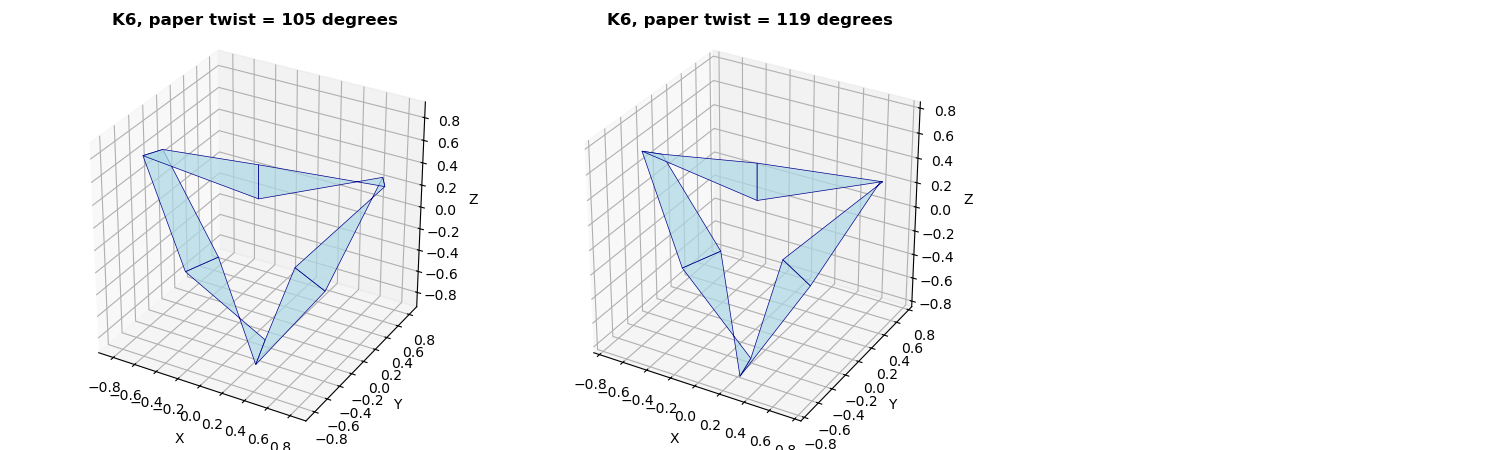

In [5]:
fig = plt.figure(figsize=(15, 4.5))
for subplot, angle in enumerate((105.0, 119.0), start=1):
    cycle = Kaleidocycle(curve=constructed[angle]["curve"])
    axis = fig.add_subplot(1, 3, subplot, projection="3d")
    cycle.plot(ax=axis, title=f"K6, paper twist = {angle:.0f} degrees")
plt.tight_layout()
plt.show()

In [5]:
def alternating_k6_residual(flat_hinges, alpha):
    hinges = np.asarray(flat_hinges).reshape(7, 3)
    adjacent_dots = np.sum(hinges[:-1] * hinges[1:], axis=1)
    return np.concatenate(
        (
            np.sum(hinges[:-1] ** 2, axis=1) - 1.0,
            closure_residual(hinges),
            hinges[0] + hinges[-1],
            adjacent_dots - expected_curve_cosines(alpha),
        )
    )


def fit_threefold_rotation_error(curve):
    points = curve[:-1] - np.mean(curve[:-1], axis=0)
    shifted = np.roll(points, -2, axis=0)
    left, _, right_transpose = np.linalg.svd(points.T @ shifted)
    rotation = right_transpose.T @ left.T
    if np.linalg.det(rotation) < 0.0:
        right_transpose[-1] *= -1.0
        rotation = right_transpose.T @ left.T
    fitted = (rotation @ points.T).T
    error = np.max(np.linalg.norm(fitted - shifted, axis=1))
    angle = np.arccos(np.clip((np.trace(rotation) - 1.0) / 2.0, -1.0, 1.0))
    return float(error), float(np.rad2deg(angle))


def find_k6(alpha_degrees, seed=3):
    alpha = np.deg2rad(alpha_degrees)
    initial = random_hinges(6, seed=seed, oriented=False).as_array()
    result = least_squares(
        alternating_k6_residual,
        initial.ravel(),
        args=(alpha,),
        max_nfev=3000,
        ftol=1e-13,
        xtol=1e-13,
        gtol=1e-13,
    )
    hinges = result.x.reshape(7, 3)
    cycle = Kaleidocycle(hinges=hinges)
    residual = alternating_k6_residual(result.x, alpha)
    symmetry_error, symmetry_angle = fit_threefold_rotation_error(cycle.curve)
    return {
        "alpha_degrees": float(alpha_degrees),
        "cycle": cycle,
        "result": result,
        "max_residual": float(np.max(np.abs(residual))),
        "residual_norm": float(np.linalg.norm(residual)),
        "symmetry_error": symmetry_error,
        "symmetry_angle": symmetry_angle,
    }

In [6]:
numerical_solutions = {angle: find_k6(angle) for angle in sample_angles}

print(" alpha   success   max residual   3-fold error   fitted rotation")
for angle, solution in numerical_solutions.items():
    print(
        f"{angle:6.1f}   {str(solution['result'].success):>7}"
        f"   {solution['max_residual']:12.2e}"
        f"   {solution['symmetry_error']:12.2e}"
        f"   {solution['symmetry_angle']:8.3f} degrees"
    )

assert all(solution["result"].success for solution in numerical_solutions.values())
assert max(solution["max_residual"] for solution in numerical_solutions.values()) < 1e-11
assert max(solution["symmetry_error"] for solution in numerical_solutions.values()) < 1e-11

 alpha   success   max residual   3-fold error   fitted rotation
  90.0      True       1.11e-15       1.85e-15    120.000 degrees
  95.0      True       3.11e-14       2.23e-14    120.000 degrees
 100.0      True       2.22e-16       5.93e-16    120.000 degrees
 105.0      True       4.44e-16       1.52e-15    120.000 degrees
 110.0      True       2.22e-16       6.00e-16    120.000 degrees
 115.0      True       8.88e-16       8.67e-16    120.000 degrees
 119.0      True       3.55e-15       7.69e-15    120.000 degrees
 119.9      True       2.22e-16       5.08e-15    120.000 degrees
